<a href="https://colab.research.google.com/github/Lviso/Apache-Spark-with-Python---Big-Data-with-PySpark-and-Spark/blob/master/Activity2_BigData_LuisVisoFinal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 2: Data analysis with PySpark

In this activity, we will work with Apache PySpark to analize some heterogeneous data in some of the ways that PySpark allows us to. We will work with unstructured data (text), semi-structured data (json) and structured data (csv) and extract some insights from them using the Spark RDD API, the Spark DataFrame API, and the Spark SQL API. Finally, we will build a Machine Learning pipeline with Spark's MLlib, where we will see how to preprocess and normalize the data to feed it into a classifier.

## Completion instructions

You will have to fill in the pieces of code that are marked with **\<FILL_IN\>** in the code cells. After each of the code cells, you will find a cell with an `assert` statement that will check that your results are correct. Thus, you can self-evaluate your work before submitting it.

## Evaluation

This activity is split in 4 parts, dealing with different types of data and a 4th part which uses Spark's ML lib to build a classifier.

- Unstructured data (2 points) (6 asserts)
- Semi-structured data (4 points) (10 asserts)
- Structured data (3 points) (12 asserts)
- Machine Learning (1 point) (7 asserts)

## Set up environment

First we set up our pyspark environment importing the core libraries we will need. Later, we will import more libraries as needed.

Depending on where we are running this activity, our local cluster from Activity 1 or Google Colab, the set up will be a bit different. Run **ONLY** the one you are in.

### Set up in the local cluster
In our local cluster, well just need to find the pyspark installation.

### Set up in Google Colab
We need to install pyspark in the Colab session and grant access to our Google Drive account.

In [167]:
!pip install -q pyspark

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Import libraries

This is the same for both setups.

In [168]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

### Configure the Spark Session
For the Application Name, call it `'Activity 2'`, and for master, choose `'yarn'` if running on your local cluster, or `'local[*]'` if running on Google Colab.

In [169]:
spark = SparkSession.builder.appName('Activity 2').master("local[*]").getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

> ✋**Configure the Spark Session**
>
>This cell presents itself as the foundation of my understanding of a Spark Cluster. The first question I asked myself was where this *SparkSession* is running. By setting  *local*[*], it runs on the virtual machine allocated to my Google Collab instance, utilizing all available cores as parallel execution threads.
>
>As the video lecture states, it is interesting to realize that the transition from a learning environment to an enterprise production environment is completely seamless, making easier to work in a testing environment before jumping to an execution environment, where,  however, we must carefully analyze and optimize data locality, serialization overhead, and data access efficiency to ensure optimal performance across the nodes.
>
>Google Colab acts as a single-node host running a JVM within this host. The JVM acts as both the Driver and the Executors, which run the parallel processing tasks as threads rather than separate physical servers.
>
>**Check Google Colab assigned resources:**
</span>

In [170]:
print("=== CPU Specs ===")
!lscpu | grep -E "Model name|Core\(s\) per socket|Thread\(s\) per core|CPU\(s\):"

print("\n=== Memory ===")
!free -h

print("\n=== Disk Space ===")
!df -h / | awk '{print "Total: " $2 ", Used: " $3 ", Available: " $4}'

=== CPU Specs ===
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Core(s) per socket:                      1
NUMA node0 CPU(s):                       0,1

=== Memory ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.6Gi       7.7Gi        23Mi       2.7Gi        10Gi
Swap:             0B          0B          0B

=== Disk Space ===
Total: Size, Used: Used, Available: Avail
Total: 226G, Used: 802M, Available: 226G


## Unstructured data (Text with RDDs)
First, we will analyze a text file, namely counting the words of text files, using Spark's RDD API. Note that we could also use the Structured API to analyze text files, but we will use that API in the next sections. For now, we will use the RDD API as a proxy to MapReduce (it is not the same, since Spark allows us to chain operations).

To do so we will build a `wordCount` function which can work with real-world data, which usually have issues like the use of uppercase and lowercase, punctuation, accents, etc. Then, we will load the file from our data source and, finally, count the words from the processed file.

### Creating a WordCount function

First define a function to count words. To do so, you should take an RDD that contains a list of words and return a pair RDD with all words with the corresponding counts.

In [171]:
def wordCount(wordListRDD):
    """Creates a pair RDD with word counts from an RDD of words.

    Args:
        wordListRDD (RDD of str): An RDD consisting of words.

    Returns:
        RDD of (str, int): An RDD consisting of (word, count) tuples.
    """
    #first map will map each word to a tuple pairRDD,
    #then reduceByKey will add the values of each Key

    return wordListRDD.map(lambda word: (word, 1)).reduceByKey(lambda a, b: a + b)

In [172]:
wordsList = ['cat', 'elephant', 'rat', 'rat', 'cat']
wordsRDD = sc.parallelize(wordsList)
assert sorted(wordCount(wordsRDD).collect())==[('cat', 2), ('elephant', 1), ('rat', 2)],'incorrect definition for wordCount function'

### Cleaning up: uppercase and punctuation

Real world text files are usually quite complex. Some of the usual problems that need to be solved are:
  + Words need to be counted whether they are uppercase or lowercase (e.g., Spark and spark are the same word).
  + Punctuation needs to be removed.
  + Trailing spaces (spaces at the beginning or end of words) should be removed.

Define the function `removePunctuation` that converts the text to lowercase, removes punctuation and trailing spaces. Use the  [re](https://docs.python.org/3/library/re.html) Python built-in library to remove any character that is not a letter, a number or a space.

**Hints**

1. Use the function [re.sub()](https://docs.python.org/3/library/re.html#re.sub).
2. For our purposes, "punctuation" means non-alphabetic, numeric or space. The regular expression for that is `[^A-Za-z\s\d]`.
3. Do not use `\W`, since it will retain lowerscores.

In [173]:
import re
def removePunctuation(text):
    """Removes punctuation, changes to lower case, and strips leading and trailing spaces.

    Note:
        Only whitespace, letters, and numbers should be retained.  Other characters should should be
        eliminated (e.g. it's becomes its).  Leading and trailing spaces should be removed after
        punctuation is removed.

    Args:
        text (str): A string.

    Returns:
        str: The cleaned up string.
    """
    #tex.lower() to lower case
    #.strip() to remove blank spaces begginind and end of the string if exits
    #re.sub to replace '' by any expression but ^ letters, spaces, and digits
    return re.sub(r'[^A-Za-z\s\d]', '', text.lower().strip())

In [174]:
assert removePunctuation(" The Elephant's 4 cats. ") == 'the elephants 4 cats', 'incorrect definition for removePunctuation function'

### Loading text files

Load all text files in your data source. This might be the text files in your HDFS system in case you are using your local cluster or files in your Google drive.

To convert a text file to an RDD, we'll use the method `SparkContext.textFile()`.
Then, use the function `removePunctuation()` within a `map()` transformation to remove all non-alphanumeric or space characteds. Since the file is pretty big, we'll use `take(15)` to only print the first 15 lines.

In [175]:
# Or load data from Google Colab
#fileName = '/content/drive/MyDrive/UOC/BigData/Activity2/activity2_data/*.txt'
fileName = '/content/drive/MyDrive/BigData/Activity2/*.txt'

In [176]:
!ls -la /content/drive/MyDrive/BigData/Activity2/

total 693468
drwx------ 2 root root      4096 Nov 22 09:11 .
drwx------ 3 root root      4096 Nov 22 09:10 ..
-rw------- 1 root root   3551167 Nov 22 09:16 adult.csv
-rw------- 1 root root    674656 Nov 22 09:16 pg20417.txt
-rw------- 1 root root   5458199 Nov 22 09:16 shakespeare.txt
-rw------- 1 root root 700418428 Nov 22 09:15 tweets28a_sample.json


In [177]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [178]:
text = sc.textFile(fileName)
text = text.map(removePunctuation)
text.take(15)

['the project gutenberg ebook of the outline of science vol 1 of 4',
 '',
 'this ebook is for the use of anyone anywhere in the united states and',
 'most other parts of the world at no cost and with almost no restrictions',
 'whatsoever you may copy it give it away or reuse it under the terms',
 'of the project gutenberg license included with this ebook or online',
 'at wwwgutenbergorg if you are not located in the united states',
 'you will have to check the laws of the country where you are located',
 'before using this ebook',
 '',
 'title the outline of science vol 1 of 4',
 '',
 'author j arthur thomson',
 '',
 'release date january 22 2007 ebook 20417']

In [179]:
assert text.take(1)[0] == 'the project gutenberg ebook of the outline of science vol 1 of 4', 'Incorrect result'

**Own Reflection:**


> *sc.textFile* creates an inmutable, resilient data abstraction object

> **Lazy Evaluation**

> Spark didn't execute the computation until the *text.take(15)* instruction in this cell, which loads 15 elements in memory, retreives and then discards all the loaded data. The previous instructions form the graph transformation plan



### Extracting words from lines

Before using `wordcount()`, we need to solve two issues with the RDD we read (which is a list of text lines):
  + First, divide each line into spaces.
  + Then filter out empty lines.

You split lines using Python's `split(' ')`. Note that `map()` is probably not the transformation you are looking for. Think about what `split()` returns.

In [180]:
# TODO: Replace <FILL IN> with appropriate code
textWords = text.flatMap(lambda line: line.split(' ')).filter(lambda word: word != "")
textWordsCount = textWords.count()
print(textWords.top(5))
print(textWordsCount)

['zwaggerd', 'zounds', 'zounds', 'zounds', 'zounds']
1010585


In [17]:
assert textWordsCount == 1010585, 'incorrect value for loremWordsCount'
assert textWords.top(5)==['zwaggerd', 'zounds', 'zounds', 'zounds', 'zounds'], 'incorrect value for loremWordsRDD'

**Own reflection**

> *while *map()* will map 1-to-1 keeping a list where each item is a list of each line of the text, *flatmap()* will flatten multiple elements, text lines, from the input into one list. The second step is to filter empty lines, which in this RDD are 4.*



### Compute distinct words

How many distinct words are in the file?

In [181]:
distinctTextWords = textWords.distinct()
distinctWords = distinctTextWords

print(distinctWords.count())

33964


In [19]:
assert distinctWords.count()==33964, 'incorrect value for shakeWordCount'

✋**Recap**

> *so far then, using RDDs API, we have an RDD (text) which a list of the filename with the punctuations remove, another RDD (textWords) which is a list of the words contained in filename, and another RDD (distinctTextWords) with distinct words of the text in filename. It is important to remind that each of these RDDs is recomputed each time a new instruction or transformation is called unless we explicity cached the RDD, which could be very convinient if one of the RDDs is used iteratively*


### Counting words

Now we have an RDD which contains only words. We can now use the function `wordCount()` to produce a list with the word counts. To get the 15 more common words, you can use the action `takeOrdered()`.

In [182]:
top15WordsAndCounts = wordCount(textWords).takeOrdered(15, key=lambda x: -x[1])
print(top15WordsAndCounts)

[('the', 36880), ('and', 29656), ('of', 23940), ('to', 21445), ('i', 20692), ('a', 17387), ('you', 13745), ('in', 13349), ('my', 12481), ('that', 12470), ('is', 11740), ('not', 9158), ('it', 9082), ('for', 8859), ('with', 8612)]


In [22]:
assert top15WordsAndCounts== [('the', 36880), ('and', 29656), ('of', 23940),
                              ('to', 21445), ('i', 20692), ('a', 17387), ('you', 13745),
                              ('in', 13349), ('my', 12481), ('that', 12470), ('is', 11740),
                              ('not', 9158), ('it', 9082), ('for', 8859), ('with', 8612)
                             ],'incorrect value for top15WordsAndCounts'

## Semi-structured data (JSON with Structured and SQL API)

In this section, we will use Twitter data collected from the 2019 general elections in Spain. These data are in JSON format, but Spark allows us to load these data using the Structured API.

### Import data

The first thing we will do is to load this type of data. One of the most common semi-structured filetypes is [JSON](https://www.w3schools.com/js/js_json.asp), probably along with [XML](https://www.w3schools.com/xml/xml_whatis.asp).
This structure allows us to store plain text information structured as objects with key-value pairs. The structure can be hierarchichal, meaning that a key can have an object as its value.

Spark allows us to read data in many different formats. What you have to do is to [read a JSON file](https://spark.apache.org/docs/latest/sql-data-sources-json.html) from ```data/tweets28a_sample.json``` in your HDFS cluster if running this activity on your local cluster or from your Google drive.

In [23]:
# In Google Colab
filePath = '/content/drive/MyDrive/UOC/BigData/Activity2/activity2_data/tweets28a_sample.json'

In [24]:
tweets_sample = spark.read.json(filePath)

print(f"Loaded dataset contains {tweets_sample.count()} tweets.")

Loaded dataset contains 401587 tweets.


In [25]:
assert tweets_sample.count() == 401587, "Incorrect answer"

The next step is to show the loaded dataset structure. You can get information about the DataFrame structure using the `printSchema()` function of the DataFrame.

In [26]:
tweets_sample.printSchema()

root
 |-- _id: string (nullable = true)
 |-- coordinates: struct (nullable = true)
 |    |-- coordinates: array (nullable = true)
 |    |    |-- element: double (containsNull = true)
 |    |-- type: string (nullable = true)
 |-- created_at: long (nullable = true)
 |-- entities: struct (nullable = true)
 |    |-- hashtags: array (nullable = true)
 |    |    |-- element: struct (containsNull = true)
 |    |    |    |-- indices: array (nullable = true)
 |    |    |    |    |-- element: long (containsNull = true)
 |    |    |    |-- text: string (nullable = true)
 |    |-- user_mentions: array (nullable = true)
 |    |    |-- element: struct (containsNull = true)
 |    |    |    |-- id: double (nullable = true)
 |    |    |    |-- id_str: string (nullable = true)
 |    |    |    |-- indices: array (nullable = true)
 |    |    |    |    |-- element: long (containsNull = true)
 |    |    |    |-- name: string (nullable = true)
 |    |    |    |-- screen_name: string (nullable = true)
 |-- fa

Notice how the tweet structure contains several nested fields. Familiarize with this structure. Remember that not all tweets have all fields, such as the `place` field. When this occurs, the value of the field is `NULL`. See more information about the data structure frome [here](https://developer.twitter.com/en/docs/tweets/data-dictionary/overview/tweet-object).

### Queries over complex DataFrames

Now, we will query the tweets DataFrame using two different approaches. First, we will use [SQL queries](https://www.w3schools.com/sql/default.asp), such as those used in most relational database systems. Then, we will use the Structured DataFrame API provided with Spark.

#### SQL Queries

Now, we will create a temporal view named `tweets_sample` from our DataFrame in our SparkSession using [createOrReplaceTempView()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.createOrReplaceTempView.html). The lifetime of this temporary table is tied to the SparkSession that was used to create this DataFrame. Once this table is created, we can execute SQL queries from `spark.sql()`.

In [27]:
tweets_sample.createOrReplaceTempView("tweets_sample")

In [28]:
assert spark.sql("SELECT * FROM tweets_sample").count() == 401587, "Incorrect answer"

Now, you will create a DataFrame `users_agg` with [aggregate information](https://www.w3schools.com/sql/sql_groupby.asp)
of users with their language `user.lang` defined as Spanish `es`. Namely, you you need to create a table that contains the following columns:
  - **screen_name:** user name
  - **friends_count:** maximum number of people followed (see note) by this user
  - **tweets:** number of tweets
  - **followers_count:** maximum number of followers (see note) this user has

You need to order registers in descending order by the number of tweets.

***Note:*** it's important for you to check that the number of *friends* and *followers* might differ during data adquisition. In this case we will use the aggregation function `MAX` on each of these fields to prevent users from being segmented in different records.

In [29]:
query = '''
    SELECT
      user.screen_name AS screen_name,
      MAX(user.friends_count) AS friends_count,
      COUNT(*) AS tweets,
      MAX(user.followers_count) AS followers_count
    FROM tweets_sample
    WHERE user.lang = 'es'
    GROUP BY user.screen_name
    ORDER BY tweets DESC
'''

users_agg = spark.sql(query)
users_agg.limit(10).show()

+---------------+-------------+------+---------------+
|    screen_name|friends_count|tweets|followers_count|
+---------------+-------------+------+---------------+
|       anaoromi|         6322|   223|           6869|
|    RosaMar6254|         6252|   141|           6292|
|MariaJo40891027|          880|   134|            849|
|    DuroBelinda|         5246|   129|           5791|
| locuspolitikus|        11263|   120|          10261|
|   rosavergar23|          974|   109|           1294|
|  Rafa_eltorete|          930|    98|           1084|
|    CurritoRojo|         4997|    96|           4235|
| Perona10690463|         1191|    94|           1585|
|   meme_montero|         1539|    94|           1558|
+---------------+-------------+------+---------------+



In [30]:
output = users_agg.first()
assert output.screen_name == 'anaoromi' and output.friends_count == 6322 and output.tweets == 223 and output.followers_count == 6869, "Incorrect output"

Now, we want to combine the information we have generated with information about how many times some user has been retweeted. To do so, we will have to use a [JOIN](https://www.w3schools.com/sql/sql_join.asp) operation. Register the DataFrame we have just created as a temporal view with name `user_agg`.

Once registered, you have to combine this table with `tweets_sample` using an `INNER JOIN` to obtain a table with the following information:

  - **screen_name:** user name
  - **friends_count:** maximum number of people followed (see note) by this user
  - **tweets:** number of tweets
  - **followers_count:** maximum number of followers (see note) this user has
  - **retweeted:** number of retweets obtained by the user
  - **ratio_tweet_retweeted:** ratio de retweets by number of published tweets $\frac{retweets}{tweets}$

Notice that in the tweets structure, there is a field called `retweeted_status`. If this field is not empty, it means that the tweet is a retweet, and `retweeted_status` contains the original tweet, including the `screen_name` of the original author of the tweet. Thus, a `retweeted_status.user.screen_name` will tell you who is being retweeted, group and count by this field to know how many times a user has been retweeted.

The resulting DataFrame has to be ordered in descending order by the column `ratio_tweet_retweeted`.

In [31]:
users_agg.createOrReplaceTempView("user_agg")
tweets_sample.createOrReplaceTempView("tweets_sample")

query = '''
    SELECT
        u.screen_name,
        u.friends_count,
        u.tweets,
        u.followers_count,
        r.retweeted,
        (r.retweeted / u.tweets) AS ratio_tweet_retweeted
    FROM user_agg u
    INNER JOIN (
        SELECT
            retweeted_status.user.screen_name AS screen_name,
            COUNT(*) AS retweeted
        FROM tweets_sample
        WHERE retweeted_status IS NOT NULL
        GROUP BY retweeted_status.user.screen_name
    ) r ON u.screen_name = r.screen_name
    ORDER BY ratio_tweet_retweeted DESC
'''

retweeted = spark.sql(query)
retweeted.limit(10).show()

+---------------+-------------+------+---------------+---------+---------------------+
|    screen_name|friends_count|tweets|followers_count|retweeted|ratio_tweet_retweeted|
+---------------+-------------+------+---------------+---------+---------------------+
| AntonioMaestre|         1331|     1|         262284|     2009|               2009.0|
|Pablo_Iglesias_|         2831|     2|        2289182|     2013|               1006.5|
| RubenSanchezTW|          751|     1|         158867|      702|                702.0|
|sanchezcastejon|         6125|     2|        1010813|     1398|                699.0|
|  InesArrimadas|         1257|     1|         489884|      685|                685.0|
|    JonInarritu|         5113|     2|          89789|     1206|                603.0|
|jonathanmartinz|          706|     1|          93938|      576|                576.0|
| Irene_Montero_|         1868|     1|         307213|      569|                569.0|
|   GuajeSalvaje|         5942|     1|     

In [33]:
output = retweeted.first()
assert output.screen_name == 'AntonioMaestre' and output.friends_count == 1331 and output.tweets == 1 and output.followers_count == 262284 and output.ratio_tweet_retweeted == 2009.0 and output.retweeted == 2009, "Incorrect output"

#### Queries using Spark's Structured API

Spark's DataFrames offer a different mechanism to apply transformations and obtain the same results we would obtain using SQL Queries. For example, using the following pipeline would obtain the text of all tweets in Spanish:

```
tweets_spanish = tweets_sample.where("user.lang == 'es'").select("text")
```

Which is equivalent to:
```
tweets_spanish = spark.sql("SELECT text FROM tweets_sample WHERE user.lang == 'es'")
```

Check the [DataFrame API](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/dataframe.html) to find more details of DataFrame transformations and actions.

Now, you need to replicate the query in the previous section, starting with generating the `users_agg` DataFrame. You can use [where](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.where.html), [select](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.select.html), [selectExpr](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.selectExpr.html), [groupBy](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.groupBy.html), [count](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.count.html), [agg](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.agg.html) and [orderBy](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.orderBy.html).

Note that `selectExpr` allows SQL statements in the select function, and `aggr` can act on more than one column by passing a dictionary of `{'column1': 'function1', 'column2': 'function2', '*': 'function3 ...}`

In [41]:
users_agg = (tweets_sample.where("user.lang == 'es'").groupBy("user.screen_name")\
             .agg({\
                   "user.friends_count": "max",\
                   "*": "count",\
                   "user.followers_count": "max"})\
             .orderBy("count(1)", ascending=False)
            )
users_agg.limit(10).show()

+---------------+----------------------------------------+--------+--------------------------------------------+
|    screen_name|max(user.friends_count AS friends_count)|count(1)|max(user.followers_count AS followers_count)|
+---------------+----------------------------------------+--------+--------------------------------------------+
|       anaoromi|                                    6322|     223|                                        6869|
|    RosaMar6254|                                    6252|     141|                                        6292|
|MariaJo40891027|                                     880|     134|                                         849|
|    DuroBelinda|                                    5246|     129|                                        5791|
| locuspolitikus|                                   11263|     120|                                       10261|
|   rosavergar23|                                     974|     109|                             

In [43]:
output = users_agg.first()
assert output.screen_name == 'anaoromi'

You may have noticed that the column names from this operation do not correspond to the ones obtained when using the SQL API. You can change column names using the [withColumnRenamed](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.withColumnRenamed.html) transformation. Change the name of the columns so that they match the once from the previous section and save the new DataFrame as `user_agg_new`

In [47]:
users_agg_new = (users_agg.withColumnRenamed("max(user.friends_count AS friends_count)", "friends_count")\
                 .withColumnRenamed("count(1)", "tweets")\
                 .withColumnRenamed("max(user.followers_count AS followers_count)", "followers_count"))

users_agg_new.limit(10).show()

+---------------+-------------+------+---------------+
|    screen_name|friends_count|tweets|followers_count|
+---------------+-------------+------+---------------+
|       anaoromi|         6322|   223|           6869|
|    RosaMar6254|         6252|   141|           6292|
|MariaJo40891027|          880|   134|            849|
|    DuroBelinda|         5246|   129|           5791|
| locuspolitikus|        11263|   120|          10261|
|   rosavergar23|          974|   109|           1294|
|  Rafa_eltorete|          930|    98|           1084|
|    CurritoRojo|         4997|    96|           4235|
| Perona10690463|         1191|    94|           1585|
|   meme_montero|         1539|    94|           1558|
+---------------+-------------+------+---------------+



In [53]:
output = users_agg_new.first()
assert output.screen_name == 'anaoromi' and output.friends_count == 6322 and output.tweets == 223 and output.followers_count == 6869, "Incorrect output"

Create now a `user_retweets` DataFrame using transformations that contains two column:
- ***screen_name***: user name
- ***retweeted***: number of retweets received by this user

You have done a similar thing before using SQL and JOINs, we will not use the joins yet, we will just create this DataFrame. Order the DataFrime in descending order by the number of retweets. Make sure to rename the needed columns and to filter out (where) null screen names.

In [55]:
user_retweets = (tweets_sample.where(F.col("retweeted_status").isNotNull())\
                 .groupBy(F.col("retweeted_status.user.screen_name").alias("screen_name"))\
                 .agg(F.count("*").alias("retweeted"))\
                 .where(F.col("screen_name").isNotNull())\
                 .orderBy(F.col("retweeted").desc())
)

user_retweets.limit(10).show()

+---------------+---------+
|    screen_name|retweeted|
+---------------+---------+
|         vox_es|     4653|
|  Santi_ABASCAL|     3188|
|           KRLS|     2916|
|   ahorapodemos|     2897|
|           PSOE|     2416|
|         boye_g|     2244|
|Pablo_Iglesias_|     2013|
| AntonioMaestre|     2009|
|       iescolar|     1959|
|      JuntsXCat|     1874|
+---------------+---------+



In [56]:
output = user_retweets.first()
assert output.screen_name == 'vox_es' and output.retweeted == 4653, "Incorrect output"

Now, we will [join](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.join.html) `users_agg_new` with `user_retweets` to obtain something close to what we had in the previous section using SQL. Combine these two tables into a new one called `retweeted` using the column `screen_name`. Order the new table in descending order by the number of retweets.

The second parameter of the join function is `on` which tells us which column has to be used to execute the join. You can access column names as if they were objects, `dataframe_name.column_name`. Another way is to use the [col](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.col.html) function. We imported this function at the beginning with `import pyspark.sql.functions as F`, so you can call this function as `F.col("column_name")` to access a column.

In [61]:
retweeted = (users_agg_new.join(user_retweets, \
              on=users_agg_new.screen_name == user_retweets.screen_name,how="inner")\
              .orderBy("retweeted", ascending=False))


retweeted.limit(10).show()

+---------------+-------------+------+---------------+---------------+---------+
|    screen_name|friends_count|tweets|followers_count|    screen_name|retweeted|
+---------------+-------------+------+---------------+---------------+---------+
|         vox_es|         1018|    26|         259373|         vox_es|     4653|
|  Santi_ABASCAL|         3965|     8|         230201|  Santi_ABASCAL|     3188|
|   ahorapodemos|         1589|    14|        1390728|   ahorapodemos|     2897|
|           PSOE|        13646|    22|         688356|           PSOE|     2416|
|         boye_g|          698|     6|         152081|         boye_g|     2244|
|Pablo_Iglesias_|         2831|     2|        2289182|Pablo_Iglesias_|     2013|
| AntonioMaestre|         1331|     1|         262284| AntonioMaestre|     2009|
|       iescolar|         5573|     5|         940166|       iescolar|     1959|
|      JuntsXCat|          234|    24|          91560|      JuntsXCat|     1874|
|   CiudadanosCs|        929

In [62]:
output = retweeted.first()
assert output.screen_name == 'vox_es' and output.friends_count == 1018 and output.tweets == 26 and output.followers_count == 259373 and output.retweeted == 4653, "Incorrect output"

To finish this part, and obtain a table equal to the one in the previous section, we need to include the column `ratio_tweet_retweeted` with the information  $\frac{retweets}{tweets}$. To do so, you can use the transformation
[withColumn](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.withColumn.html).
Order the result in descending order using this new column.

In [63]:
retweeted = (retweeted.withColumn("ratio_tweet_retweeted", F.col("retweeted")\
                / F.col("tweets")).orderBy("ratio_tweet_retweeted", ascending=False))

retweeted.limit(10).show()

+---------------+-------------+------+---------------+---------------+---------+---------------------+
|    screen_name|friends_count|tweets|followers_count|    screen_name|retweeted|ratio_tweet_retweeted|
+---------------+-------------+------+---------------+---------------+---------+---------------------+
| AntonioMaestre|         1331|     1|         262284| AntonioMaestre|     2009|               2009.0|
|Pablo_Iglesias_|         2831|     2|        2289182|Pablo_Iglesias_|     2013|               1006.5|
| RubenSanchezTW|          751|     1|         158867| RubenSanchezTW|      702|                702.0|
|sanchezcastejon|         6125|     2|        1010813|sanchezcastejon|     1398|                699.0|
|  InesArrimadas|         1257|     1|         489884|  InesArrimadas|      685|                685.0|
|    JonInarritu|         5113|     2|          89789|    JonInarritu|     1206|                603.0|
|jonathanmartinz|          706|     1|          93938|jonathanmartinz|   

In [64]:
output = retweeted.first()
assert output.screen_name == 'AntonioMaestre' and output.friends_count == 1331 and output.tweets == 1 and output.followers_count == 262284 and output.ratio_tweet_retweeted == 2009.0 and output.retweeted == 2009, "Incorrect output"

Can you get the `retweeted` DataFrame on a single (pretty long) instruction? You may need to do some column renaming for the join to work correctly.

In [66]:
retweeted = (
    tweets_sample.where("user.lang == 'es'")
    .groupBy("user.screen_name") # 1 - filtering and aggrupation of all tweets
    .agg(                        # 2 - user aggregation with column rename using spark_sql_functions
        F.max("user.friends_count").alias("friends_count"),
        F.count("*").alias("tweets"),
        F.max("user.followers_count").alias("followers_count")
    ) # we build dataframe users_agg_new
    .join( # 3 - join users_agg_new with a second dataframe grouped by retweets equivalent to user_retweets
        tweets_sample.where(F.col("retweeted_status").isNotNull())
        .groupBy(F.col("retweeted_status.user.screen_name").alias("rt_screen_name"))
        .agg(F.count("*").alias("retweeted"))
        .where(F.col("rt_screen_name").isNotNull()),#remove retweets with screen_name null
        on=F.col("screen_name") == F.col("rt_screen_name"),
        how="inner"
    )
    #ratio calculation and ordering
    .withColumn("ratio_tweet_retweeted", F.col("retweeted") / F.col("tweets"))
    .orderBy(F.col("ratio_tweet_retweeted").desc())
    .drop("rt_screen_name")
)

retweeted.limit(10).show()

+---------------+-------------+------+---------------+---------+---------------------+
|    screen_name|friends_count|tweets|followers_count|retweeted|ratio_tweet_retweeted|
+---------------+-------------+------+---------------+---------+---------------------+
| AntonioMaestre|         1331|     1|         262284|     2009|               2009.0|
|Pablo_Iglesias_|         2831|     2|        2289182|     2013|               1006.5|
| RubenSanchezTW|          751|     1|         158867|      702|                702.0|
|sanchezcastejon|         6125|     2|        1010813|     1398|                699.0|
|  InesArrimadas|         1257|     1|         489884|      685|                685.0|
|    JonInarritu|         5113|     2|          89789|     1206|                603.0|
|jonathanmartinz|          706|     1|          93938|      576|                576.0|
| Irene_Montero_|         1868|     1|         307213|      569|                569.0|
|   GuajeSalvaje|         5942|     1|     

In [67]:
output = retweeted.first()
assert output.screen_name == 'AntonioMaestre' and output.friends_count == 1331 and output.tweets == 1 and output.followers_count == 262284 and output.ratio_tweet_retweeted == 2009.0 and output.retweeted == 2009, "Incorrect output"


✋**Own Reflection:**

> *This exercise with the Spark SQL API proved the importance of knowing well how Spark works. Firstly, as with RDDs, the creation of the DAG will set the pipeline to collect and work with the data. Beyond knowing all the commands, and especially nowadays with the support of LLMs, the key for the data analyst is to fully understand how to work with the partitions in the most efficient way for large datasets. Intrinsically, this points to knowing very well the structure of the datasets to perform transformations and actions at the lowest computational cost.*

## Structured data (CSV data)

In this section, we will analyze a comma-separated value (CSV) dataset named Adult. This dataset contains demographic and job-related attributes of some over 30 thousand individuals, and is typically used to test machine learning classification tasks.
This dataset, however, needs some cleaning and preprocessing to be useful to us, so we can use it to practice some of the Spark functionalities related to that.

### Load data

Load the `adult.csv` file from either your HDFS cluster or from Google Drive.
The adult file is a `csv` file with a header.

Here's the structure of the dataset:
 - age: integer
 - workclass: string
 - fnlwgt: integer
 - education: string
 - education_num: integer
 - marital_status: string
 - occupation: string
 - relationship: string
 - race: string
 - sex: string
 - capital_gain: integer
 - capital_loss: integer
 - hours_per_week: integer
 - native_country: string
 - class: string

To make sure that the file is loaded correctly, we will define a custom schema, so that Spark knows how to interpret each of the attributes. We will then load the `csv` file with [spark.read.csv()](https://spark.apache.org/docs/latest/sql-data-sources-csv.html). We can pass the custom schema via the `schema` parameter of the `spark.csv.read()` function.

A [schema](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.schema.html) defines the attribute names and daty types of a DataFrame, and consists of a [StructType](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.types.StructType.html) object, which basically represents each *row* of our data. StructTypes contain multiple [StructField](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.types.StructField.html) objects, which describe each of the attributes in the *row*, including their name, their [data types](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/data_types.html), and whether they are nullable or not.

First, provide the path to the `csv` file according to your settings.

In [183]:
# Load from Google Drive
filePath = 'drive/MyDrive/BigData/Activity2/adult.csv'

Let's define the schema. What you want to do is to build a StructType() object, initialized with a **list** of StructTypes, each of them initialized with their name, their data type and whether they are nullable (in this case, set the nullable parameter to True for all attributes).

```python
schema = StructType([StructField("field_name1", SomeType(), True), StructField(...), ..., ])
```

Follow the structure above to name the fields and set their types. Then, load the dataset with `spark.read.csv(...)`, setting the custom schema, and the `header` parameter to `True`.

In [184]:
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

schema = StructType([
    StructField("age", IntegerType(), True),
    StructField("workclass", StringType(), True),
    StructField("fnlwgt", IntegerType(), True),
    StructField("education", StringType(), True),
    StructField("education_num", IntegerType(), True),
    StructField("marital_status", StringType(), True),
    StructField("occupation", StringType(), True),
    StructField("relationship", StringType(), True),
    StructField("race", StringType(), True),
    StructField("sex", StringType(), True),
    StructField("capital_gain", IntegerType(), True),
    StructField("capital_loss", IntegerType(), True),
    StructField("hours_per_week", IntegerType(), True),
    StructField("native_country", StringType(), True),
    StructField("class", StringType(), True)
])

adult_custom_schema = spark.read.csv(filePath, header=True, schema=schema)

adult_custom_schema.printSchema()

root
 |-- age: integer (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: integer (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: integer (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: integer (nullable = true)
 |-- capital_loss: integer (nullable = true)
 |-- hours_per_week: integer (nullable = true)
 |-- native_country: string (nullable = true)
 |-- class: string (nullable = true)



In [76]:
assert adult_custom_schema.schema == spark.read.option('header', True).option("inferSchema", True).csv(filePath).schema, "Incorrect Result"

As you can see from the `assert` instruction just above, and by the exercices with semi-structured data, Spark is able to infer the schema of your dataset if it is not ambiguous. You may attempt to always load your data trying to infer the schema, but make sure to always check the inferred schema with `printSchema()`, since ambiguous fields may be inferred incorrectly.

In [185]:
adult = spark.read.csv(filePath, header=True, inferSchema=True)
adult.printSchema()

root
 |-- age: integer (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: integer (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: integer (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: integer (nullable = true)
 |-- capital_loss: integer (nullable = true)
 |-- hours_per_week: integer (nullable = true)
 |-- native_country: string (nullable = true)
 |-- class: string (nullable = true)



In [186]:
assert adult.count() == 32561, "Incorrect result"

### Data preprocessing: cleaning and casting

The first thing we will do with our dataset is to look for missing values. It is common for datasets to have missing or incorrect entries, which we need to locate and deal with.

Print all distinct values of the `native_country` column. Order the results by `native_country`. You can pass an integer value to the `.show()` function to indicate how many rows you want to print, set it at 50 to make sure you do not miss any value.

In [187]:
distinctNativeCountry = adult.select("native_country").distinct().orderBy("native_country")
distinctNativeCountry.show(50)

+--------------------+
|      native_country|
+--------------------+
|                   ?|
|            Cambodia|
|              Canada|
|               China|
|            Columbia|
|                Cuba|
|  Dominican-Republic|
|             Ecuador|
|         El-Salvador|
|             England|
|              France|
|             Germany|
|              Greece|
|           Guatemala|
|               Haiti|
|  Holand-Netherlands|
|            Honduras|
|                Hong|
|             Hungary|
|               India|
|                Iran|
|             Ireland|
|               Italy|
|             Jamaica|
|               Japan|
|                Laos|
|              Mexico|
|           Nicaragua|
|Outlying-US(Guam-...|
|                Peru|
|         Philippines|
|              Poland|
|            Portugal|
|         Puerto-Rico|
|            Scotland|
|               South|
|              Taiwan|
|            Thailand|
|     Trinadad&Tobago|
|       United-States|
|          

In [188]:
assert distinctNativeCountry.first()['native_country'] == '?', "Incorrect result"

Notice that the first result is `?`, which suggests this is missing information. Other string attributes in the dataset also contain this missing values. But since `?` is a valid string, Spark has not correctly identified them as missing values. There are two avenues to tackle this issue. One possibility, if all missing values are denoted in the same way (note that some datasets may use different values for missing values in different attributes), we can just reload the dataset including the option `nullValue` and indicating which string should be interpreted as a missing value, in this case `?`.

In case missing values are identified by different strings, you can use the transformation [replace()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.replace.html) to replace specific strings to the value `None`.

Choose the approach you prefer.

In [189]:
adult = adult.replace("?", None)
adult.show()

+---+----------------+------+------------+-------------+--------------------+-----------------+-------------+------------------+------+------------+------------+--------------+--------------+-----+
|age|       workclass|fnlwgt|   education|education_num|      marital_status|       occupation| relationship|              race|   sex|capital_gain|capital_loss|hours_per_week|native_country|class|
+---+----------------+------+------------+-------------+--------------------+-----------------+-------------+------------------+------+------------+------------+--------------+--------------+-----+
| 39|       State-gov| 77516|   Bachelors|           13|       Never-married|     Adm-clerical|Not-in-family|             White|  Male|        2174|           0|            40| United-States|<=50K|
| 50|Self-emp-not-inc| 83311|   Bachelors|           13|  Married-civ-spouse|  Exec-managerial|      Husband|             White|  Male|           0|           0|            13| United-States|<=50K|
| 38|     

In [190]:
assert adultNA.dropna().count() == 30162, "Incorrect result"

Once missing values are correctly identified, you need to choose a strategy to deal with them. One option is to fill the missing values with specific values using the [fillna()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.fillna.html) transformation. You can pass a dictionary to the function, so that each missing values from each attribute are treated differently.

In our case, however, we will just drop all rows which contain missing values, using the [dropna()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.dropna.html) transformation.

In [191]:
adultNA = adult.dropna()
adultNA.count()

30162

In [192]:
assert adultNA.dropna().count() == 30162, "Incorrect result"

Deal with the `class` attribute, which is now a string column.

In [193]:
adult.select("class").distinct().show()

+-----+
|class|
+-----+
|<=50K|
| >50K|
+-----+



We can see there are two classes: `<=50K` and `>50K`. We will transform these to `0` and `1`. You can do so using the `withColumn` function, which can add new columns or alter existing columns given some expression. We will use the `when` function from `pyspark.sql.functions`. As we did before, you can call this function with `F.when(...).otherwise(...)`. Find the docs [here](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.when.html).

In [194]:
adult = adultNA.withColumn("class", F.when(F.col("class") == ">50K", 1).otherwise(0))
adult.select("class").distinct().show()

+-----+
|class|
+-----+
|    1|
|    0|
+-----+



In [195]:
assert adult.select(F.mean("class").alias('avg')).first().avg == 0.24892248524633645, "Incorrect result"

We do not always need all collumns. In our case, we will [drop()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.pandas/api/pyspark.pandas.DataFrame.drop.html?highlight=drop#pyspark.pandas.DataFrame.drop) the `fnlwgt`, since we will not need this attribute. Remember that DataFrames and RDDs are **immutable** data types, so actions do not modify these objects, but return new, modified, objects. This is why we can also append transformations one after another.

In [196]:
adult = adult.drop("fnlwgt")
adult.columns

['age',
 'workclass',
 'education',
 'education_num',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital_gain',
 'capital_loss',
 'hours_per_week',
 'native_country',
 'class']

In [197]:
assert len(adult.columns) == 14, "Incorrect result"

### Feature Analysis and Visualization

After cleaning our dataset a bit, we are going to analize it to extract some insights, including some data visualizations using Pandas and Matplotlib.

As we have been doing up until now. We will call some Spark functions to perform transformations on the data, and finally call an action to execute the DAG, transfer the results to the driver, and print them on the Jupyter Notebook. When we need to plot results, using Pandas or Matplotlib, we will do the same. One available action in Spark is the [toPandas()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.toPandas.html) function, which takes a Spark DataFrame (which is distributed among your computing nodes) and transforms it into a Pandas DataFrame (which is in the driver's memory). Of course, we need to make sure that the DataFrame we convert is small enough to fit the driver's memory, so normally only results and summaries should be converted.

After that, we can use Pandas or Matplotlib to plot results.

First, let us compute the proportion of individuals who earn over `50k`. Remember that we converted the `class` attribute, so we can just compute the average of the `class` attribute. Use the API you are more confortable with, the DataFrame API or the SQL API. In case you use the SQL API, remember to first create the temporal view. Rename the result as `avg`.

In [198]:
result = adult.select(F.mean("class").alias('avg'))
result.show()

+-------------------+
|                avg|
+-------------------+
|0.24892248524633645|
+-------------------+



In [199]:
assert result.first().avg == 0.24892248524633645, "Incorrect result"

This result indicates that the dataset is heavily imbalanced. This can often cause problems when training machine learning models. Let's keep analyzing the dataset. We know the proportion of individuals earning over 50k, but how many are there of each? Output the count of individuals of class 1 and class 0.

In [200]:
result = adult.groupBy("class").count()
result.show()

+-----+-----+
|class|count|
+-----+-----+
|    1| 7508|
|    0|22654|
+-----+-----+



In [201]:
assert result.first()['count'] == 7508, "Incorrect result"

We will now conduct further analysis to explore this imbalance. In particular, we will try to explore whether this imbalance is dependent on some special attributes, like `sex`, `race`, or `native_country`. These kinds of analyses are of particular importance in machine learning, where we should try to avoid perpetuating harmful biases related to minorities or protected groups.

We will first start by computing the same count as before, but grouping the results by `sex`. Compute the `counts` grouped by `sex` and order the results by `sex`and then `class`. *You can pass several column names to orderBy*.

In [202]:
countBySexClass = adult.groupBy("sex", "class").count().orderBy("sex", "class")
countBySexClass.show()

+------+-----+-----+
|   sex|class|count|
+------+-----+-----+
|Female|    0| 8670|
|Female|    1| 1112|
|  Male|    0|13984|
|  Male|    1| 6396|
+------+-----+-----+



In [203]:
assert countBySexClass.first()["count"] == 8670, "Incorrect result"

Let's also visualize the results using Pandas. To do so, convert the `countBySexClass` DataFrame to a Pandas DataFrame using the `toPandas()` action. Note that your result is a [pivot table](https://en.wikipedia.org/wiki/Pivot_table), so you will need to use the Pandas function [pivot()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html). I will give you the first of these already completed.

<Axes: xlabel='sex'>

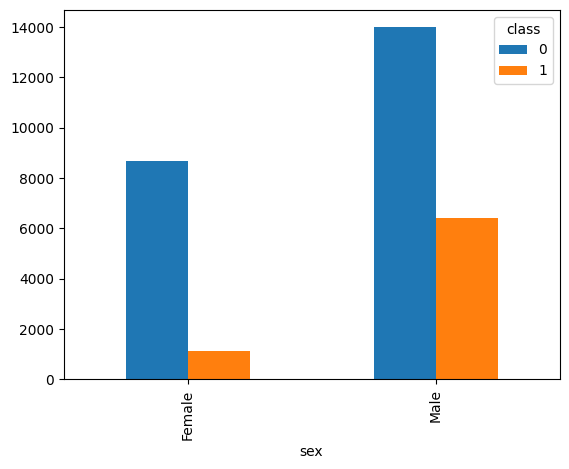

In [204]:
countBySexClass.toPandas().pivot(index="sex", columns="class", values="count").plot.bar()

Let's now see the **average class** by `sex` and `marital_status`. Again, use your preferred API and order the results by `sex`. Also, rename the average class column to `average`.

In [205]:
avgClassBySexMaritalStatus = adult.groupBy("sex", "marital_status").agg(F.mean("class").alias("average")).orderBy("sex")
avgClassBySexMaritalStatus.show()

+------+--------------------+--------------------+
|   sex|      marital_status|             average|
+------+--------------------+--------------------+
|Female|   Married-AF-spouse|                 0.5|
|Female|           Separated|0.029616724738675958|
|Female|             Widowed|  0.0597667638483965|
|Female|            Divorced| 0.06880189798339265|
|Female|  Married-civ-spouse| 0.47297297297297297|
|Female|       Never-married| 0.03780148423005566|
|Female|Married-spouse-ab...|  0.0582010582010582|
|  Male|   Married-AF-spouse|  0.4444444444444444|
|  Male|            Divorced| 0.16498516320474776|
|  Male|             Widowed|  0.2765957446808511|
|  Male|Married-spouse-ab...| 0.11049723756906077|
|  Male|  Married-civ-spouse| 0.45284068335319827|
|  Male|           Separated| 0.13424657534246576|
|  Male|       Never-married| 0.05670483930550425|
+------+--------------------+--------------------+



In [124]:
assert avgClassBySexMaritalStatus.first()["average"] == 0.5, "Incorrect result"

And plot the results as before. Use `marital_status` as index, `sex` as columns, and `average` as values.

<Axes: xlabel='marital_status'>

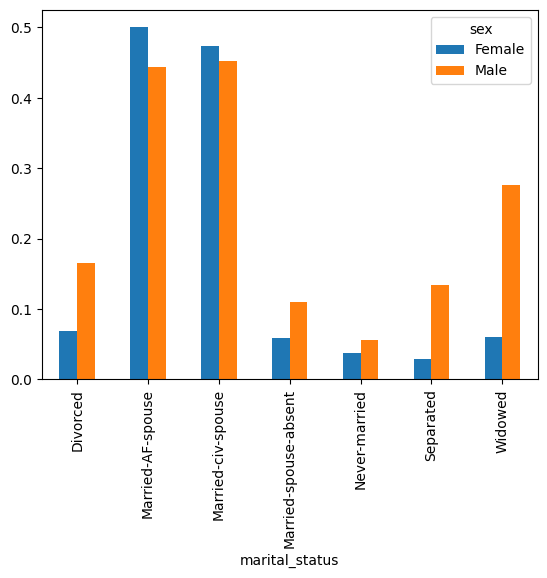

In [206]:
avgClassBySexMaritalStatus.toPandas().pivot(index="marital_status",columns="sex",\
                                            values="average").plot.bar()

Do the same for `sex` and `education`. Now order by descending `average`.

In [207]:
avgClassBySexEducation = adult.groupBy("sex", "education").agg(F.mean("class").alias("average")).orderBy("average", ascending=False)
avgClassBySexEducation.show()

+------+------------+-------------------+
|   sex|   education|            average|
+------+------------+-------------------+
|  Male| Prof-school|                0.8|
|  Male|   Doctorate| 0.7857142857142857|
|  Male|     Masters|  0.667262969588551|
|Female|   Doctorate| 0.6049382716049383|
|  Male|   Bachelors| 0.5136286201022147|
|Female| Prof-school| 0.4827586206896552|
|Female|     Masters| 0.3379174852652259|
|  Male|   Assoc-voc|0.33215962441314556|
|  Male|  Assoc-acdm|0.33115823817292006|
|  Male|Some-college| 0.2759530088707744|
|  Male|     HS-grad| 0.2084942084942085|
|Female|   Bachelors|0.20827858081471748|
|Female|  Assoc-acdm| 0.1341772151898734|
|Female|   Assoc-voc|0.13406593406593406|
|  Male|        12th|0.10588235294117647|
|  Male|        10th|                0.1|
|  Male|     7th-8th|               0.08|
|  Male|        11th|0.07533234859675036|
|Female|Some-college|0.07379337854008776|
|Female|     HS-grad|0.06857694784288473|
+------+------------+-------------

In [129]:
assert avgClassBySexEducation.first()["average"] == 0.8, "Incorrect result"

And plot the results.

<Axes: xlabel='education'>

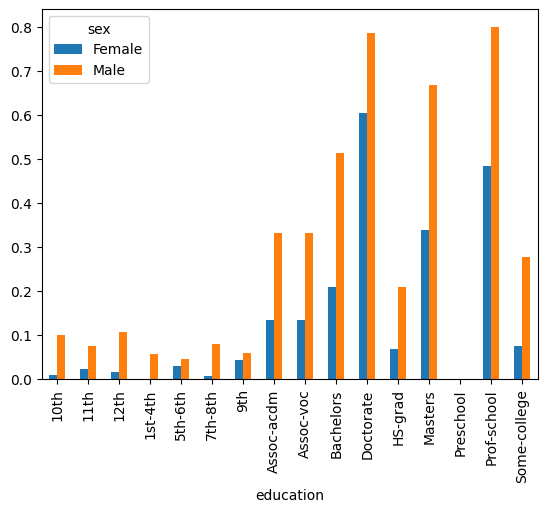

In [208]:
avgClassBySexEducation.toPandas().pivot(index="education",columns="sex",\
                                            values="average").plot.bar()

## Training a Classifier

In this final part, we will see an example of how to train a simple ML model using Spark's [MLlib](https://spark.apache.org/docs/latest/ml-guide.html) to classify the individuals in the `adult` dataset in the two classes. MLlib is Spark’s machine learning (ML) library. Its goal is to make practical machine learning scalable and easy. At a high level, it provides tools such as:

- ML Algorithms: common learning algorithms such as classification, regression, clustering, and collaborative filtering (recommender systems)
- Featurization: feature extraction, transformation, dimensionality reduction, and selection
- Pipelines: tools for constructing, evaluating, and tuning ML Pipelines
- Persistence: saving and load algorithms, models, and Pipelines
- Utilities: linear algebra, statistics, data handling, etc.

As in every ML pipeline, the steps to train the model will include preprocessing the data, transforming attributes into useful features, training the model, and evaluating it.

First, we import all necessary libraries.

In [209]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import MinMaxScaler, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import GBTClassifier, MultilayerPerceptronClassifier, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

Then, we will split the `adult` dataset into training and test datasets using the [randomSplit()](https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.randomSplit.html) transformation.

Make a 70% / 30% split, using the `42` as the value of the seed.

In [210]:
(train, test) = adult.randomSplit([0.7, 0.3], 42)

In [211]:
assert train.count() == 21174 and test.count() == 8988 and train.first()['age'] == 17, "Incorrect result"

MLlib models require very specific formatting of the input features in the form of vector columns. The library offers us a set of [tools](https://spark.apache.org/docs/latest/ml-features.html) to format the features in the desired way.

In this section we will use the following feature transformation tools:

- [VectorAssembler](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.VectorAssembler.html) to join features into feature column vectors.
- [MinMaxScaler](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.MinMaxScaler.html) to normalize numerical values.
- [StringIndexer](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.StringIndexer.html) to transform string variables into integers.
- [OneHotEncoder](https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.ml.feature.OneHotEncoder.html) to convert integers representing string variables into one-hot vectors, see this [wiki article](https://en.wikipedia.org/wiki/One-hot) to see why it's important.

While there are many more of these transformers, all of them work more or less in the same fashion. They will take the names of the columns that are fed into the transformer, and a new output column name. Additional parameters depend on the specific transformation that we apply.

First, create a VectorAssembler that takes all numerical features and assembles them into a column named `numeric_features`.

In [212]:
numericAssembler = VectorAssembler(\
    inputCols=['age', 'education_num', 'capital_gain', 'capital_loss',\
               'hours_per_week'],\
                outputCol='numeric_features')
#required by MLlib: all features should be consolidated in a column with the numerical value

In [138]:
assert numericAssembler.getInputCols() == ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week'] and numericAssembler.getOutputCol() == 'numeric_features', "Incorrect result"

Now, create a MinMaxScaler that takes as `inputCol` the `numeric_features` and returns a column named `numeric_scaled`.

In [213]:
minMaxScaler = MinMaxScaler(inputCol='numeric_features',\
                            outputCol='numeric_scaled')
#normalize numerical features

In [142]:
assert minMaxScaler.getInputCol() == 'numeric_features' and minMaxScaler.getOutputCol() == 'numeric_scaled', "Incorrect result"

Now, a StringIndexer. In this case, you will have to provide a list of the names of the string columns in the `inputCols` parameter, and a second list of column names using the same name as the input columns but appending "_indexed" to each of them.

In [214]:
stringIndexer = StringIndexer(\
    inputCols=['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country'],\
    outputCols=['workclass_indexed', 'education_indexed', 'marital_status_indexed', 'occupation_indexed', 'relationship_indexed', 'race_indexed', 'sex_indexed', 'native_country_indexed']
)
# transforming features as strings to numerical values based on its repetition
# in the dataset %%

In [150]:
assert \
stringIndexer.getInputCols() == ['workclass',
                                 'education',
                                 'marital_status',
                                 'occupation',
                                 'relationship',
                                 'race','sex',
                                 'native_country']\
and stringIndexer.getOutputCols() == ['workclass_indexed',
                                      'education_indexed',
                                      'marital_status_indexed',
                                      'occupation_indexed',
                                      'relationship_indexed',
                                      'race_indexed',
                                      'sex_indexed',
                                      'native_country_indexed'],\
"Incorrect result"

Now, we will convert the indexed columns into one-hot vectors. The OneHotEncoder takes a list of column names as `inputCols`. As you may have noticed from the previous *asserts*, you can get the column names from the previous transformers using `getOutputCols()`. Our OneHotEncoder will take the column names output by the StringIndexer, so you can make use of that. As output, it takes also a list of names. Use the same names as the StringIndexer output column, appending "_onehot". *Note: using python's map function will make this task easy.*

In [215]:
#codifying categorical features to binary codes
oneHotEncoder = OneHotEncoder(inputCols=stringIndexer.getOutputCols(),\
          outputCols=list(map(lambda x: x + "_onehot", stringIndexer.getOutputCols())))

In [216]:
assert oneHotEncoder.getInputCols() == stringIndexer.getOutputCols()\
and oneHotEncoder.getOutputCols() == ['workclass_indexed_onehot',
                                      'education_indexed_onehot',
                                      'marital_status_indexed_onehot',
                                      'occupation_indexed_onehot',
                                      'relationship_indexed_onehot',
                                      'race_indexed_onehot',
                                      'sex_indexed_onehot',
                                      'native_country_indexed_onehot'],\
"Incorrect result"

Now, we will assemble all transformed categorical features into a single column vector using a VectorAssembler that will take as input the column names from the OneHotEncoder output column names, and a single output column name called `categorical_features`.

In [217]:
categoricalAssembler = VectorAssembler(inputCols=oneHotEncoder.getOutputCols(),\
                                       outputCol="categorical_features")

In [156]:
assert categoricalAssembler.getInputCols() == oneHotEncoder.getOutputCols() and categoricalAssembler.getOutputCol() == 'categorical_features', "Incorrect result"

Almost done with preprocessing. Now assemble the `numeric_features` and the `categorical_features` into a single `features` vector column.

In [218]:
assembler = VectorAssembler(inputCols=["numeric_features", "categorical_features"],\
                            outputCol="features")

In [160]:
assert assembler.getInputCols() == ["numeric_features", "categorical_features"] and assembler.getOutputCol() == "features", "Incorrect result"

The preprocessing pipeline is ready. Now we need to instantiate our model. We will use a small Neural Network (an MLP), but any of the classifiers provided by MLlib could work in exactly the same way, aside for additional model-specific parameters.

In [219]:
mlp = MultilayerPerceptronClassifier(labelCol="class", featuresCol="features", maxIter=20, tol=1e-06, seed=42, layers=[95, 128, 128, 2], blockSize=64)

We can now chain all transformations and model into a single pipeline, which will be called in successive stages when training and making predictions.

In [220]:
pipeline = Pipeline(stages=[numericAssembler, minMaxScaler, stringIndexer, oneHotEncoder, categoricalAssembler, assembler, mlp])

And train the model.

In [163]:
# Train model.  This also runs the transformers.
model = pipeline.fit(train)


✋
> **Final Reflection**
>
> we have created the pipeline or the DAG's stages for our Spark job:
>
> 1.   NumericAssembler, to group all numeric features
2.   minMaxScaler, to normalize
3.   stringIndexer, to convert string to numerical values
4.   oneHotEncoder, to convert them to binary
5.   categoricalAssembler, a vector of the binnary features
6.   assembler, to create a unique vector of numerical features
7.   mlp, the perceptron where this features will be the input
>
>
> This is the most fascinating part for me. Two main lessons I get: (i) Lazy Computation, until the trainning call 'pipeline.fit()', Spark do not access any partition. (ii) the working nodes will train the model in a distributed manner, each working node is assigned with a task to train the mlp with the 95 features, that is, access the 95 features of its partition, execute all the stages and train the model, forward and backward propation. Finally, the master node will reduce all the gradients given by the working nodes at each epoch, at the end obtaining a tranined network through a distributed computation cluster.
>**mlflow** lib could be used to monitor the epoch metrics and the model convergence for longer trainning models, and of course **Spark UI** to monitor all the stages, jobs and worker nodes resource utilization









In [221]:
# Make predictions.
predictions = model.transform(test)

# Evaluate the model
evaluator = MulticlassClassificationEvaluator(labelCol="class", predictionCol="prediction", metricName="accuracy")
accuracy = evaluator.evaluate(predictions)
print(f"Accuracy = {accuracy}")

gbtModel = model.stages[-1]
print(gbtModel)  # summary only

Accuracy = 0.771473075211393
MultilayerPerceptronClassificationModel: uid=MultilayerPerceptronClassifier_50d5150077b8, numLayers=4, numClasses=2, numFeatures=95
